In [7]:
import pandas as pd
import rdkit
from rdkit import Chem
from rdkit.Chem import rdRGroupDecomposition
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw, AllChem
from rdkit.Chem import rdDepictor
from itertools import product # for generating all possible combinations
from rdkit.Geometry import Point2D
import requests

#### Enter the Molecule of interest

In [8]:
parent_smiles = input("Enter the SMILES of the molecule: ")
mol = Chem.MolFromSmiles(parent_smiles)

if mol is None:
    print("Invalid Molecule")

else:
    print("________________________________")
    print("Hurray!! its a valid molecule")
    print(f"The entered SMILES is {parent_smiles}")
    print(f"Canonical SMILES: {Chem.MolToSmiles(mol)}")

________________________________
Hurray!! its a valid molecule
The entered SMILES is CC(=O)NC1=CC=C(C=C1)O
Canonical SMILES: CC(=O)Nc1ccc(O)cc1


#### Visualizing the molecule

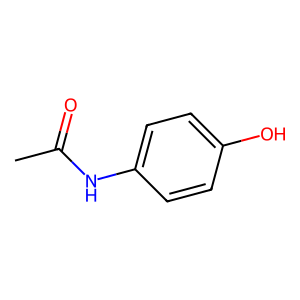

In [9]:
Draw.MolToImage(mol)

In [10]:
parent_mol = Chem.Mol(mol)
print(mol)
print(parent_mol)

In [16]:
from molecular_analogue_generator.fragment_utils import (
    set_original_idx,
    set_original_bond_idx,
    find_current_idx,
    find_current_bond_idx,
    get_core_dummy_info,
    get_replacement_dummy_info,
)

In [17]:
parent = set_original_idx(parent_mol)
parent = set_original_bond_idx(parent_mol)

In [18]:
from molecular_analogue_generator.visualization import draw_with_original_bond_indices

In [19]:
from molecular_analogue_generator.replacement_groups import replacement_groups

In [20]:
from molecular_analogue_generator.replacement_selector import (select_categories, collect_replacements, prepare_replacement_groups) 

### Automatic generation of the core

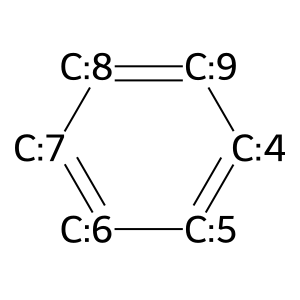

In [21]:
generate_core = input(
    "Do you wish to automatically generate core: y/n: "
)

if generate_core.upper() == "Y":
    core = MurckoScaffold.GetScaffoldForMol(parent_mol)

else:

    core_smiles = input("Enter the smiles of the core molecule")
    core = Chem.MolFromSmiles(core_smiles)

Draw.MolToImage(core)

### Generating fragments/analogues through Fragmentation/replacement of side chains

In [22]:
from molecular_analogue_generator.attachment import attach_replacement


-----------------------------
Available molecules:
-----------------------------
0 : Parent

Choose an option:
1 - Fragment a molecule
2 - Replace a bond and create molecular analogues
3 - Display molecules
4 - Finish

Which molecule do you want to modify?
0 : Parent

Selected molecule: Parent


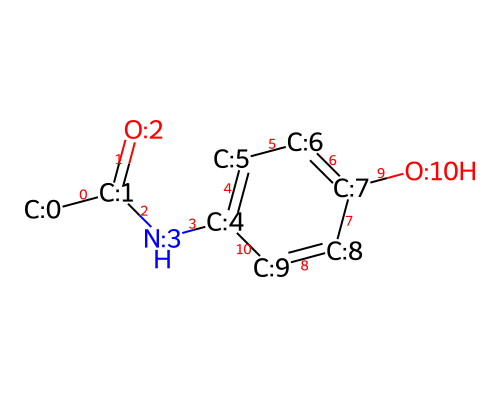


Generated core fragment:
[CH3:0][C:1](=[O:2])[NH:3][c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1


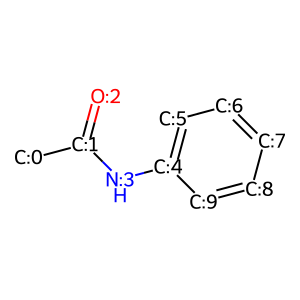


Parent_break_7_10 added to molecule library.

-----------------------------
Available molecules:
-----------------------------
0 : Parent
1 : Parent_break_7_10

Choose an option:
1 - Fragment a molecule
2 - Replace a bond and create molecular analogues
3 - Display molecules
4 - Finish

Which molecule do you want to modify?
0 : Parent
1 : Parent_break_7_10

Selected molecule: Parent


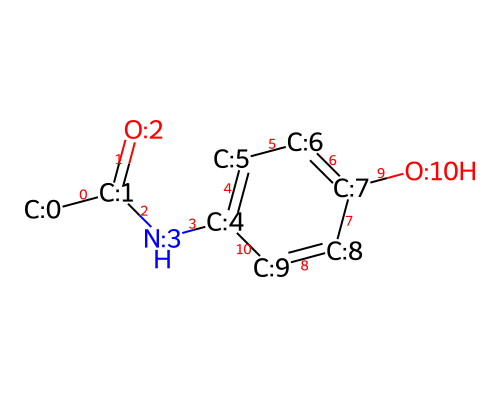


Generated core fragment:
[10*][c:7]1[cH:6][cH:5][c:4]([NH:3][C:1]([CH3:0])=[O:2])[cH:9][cH:8]1


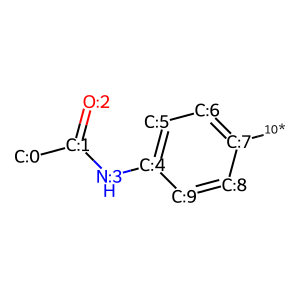


Selecting replacements for core neighbour index 7

Select categories for dummy neighbor 7
-------------------------------------------
0 | alkyl
1 | cycloalkyl
2 | alkenyl_alkynyl
3 | halogens
4 | fluoroalkyl
5 | alkoxy
6 | fluoroalkoxy
7 | oxygen
8 | amines
9 | amides
10 | carbonyl
11 | nitrile
12 | sulfur
13 | phenyl
14 | halophenyl
15 | substituted_phenyl
16 | pyridyl
17 | diazines
18 | five_membered_heteroaryl
19 | saturated_heterocycles
20 | nitrogen_carbonyl
21 | polar_groups
22 | bioisosteres
Selected categories: ['alkoxy']

Selected replacement groups:

Core neighbour index 7:
  - methoxy: [*:1]OC
  - ethoxy: [*:1]OCC
  - n_propoxy: [*:1]OCCC
  - isopropoxy: [*:1]OC(C)C
  - n_butoxy: [*:1]OCCCC
  - isobutoxy: [*:1]OCC(C)C
  - tert_butoxy: [*:1]OC(C)(C)C
  - cyclopropoxy: [*:1]OC1CC1
  - cyclobutoxy: [*:1]OC1CCC1
  - cyclopentoxy: [*:1]OC1CCCC1
  - cyclohexoxy: [*:1]OC1CCCCC1

Generating analogues for Fragment_2
Fragment_2_Analogue_1 | methoxy | CO[c:7]1[cH:6][cH:5][c:4]([NH:3][

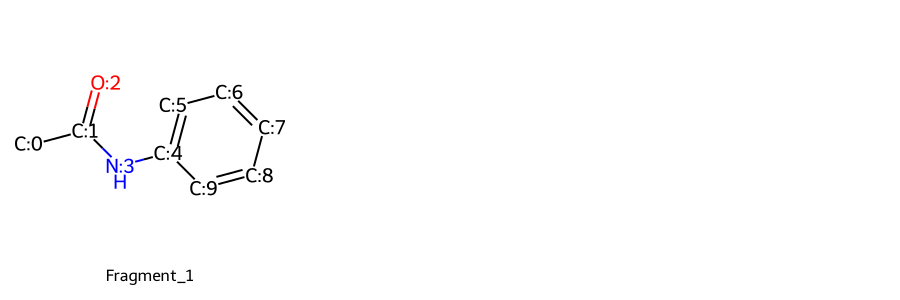


Generated dummies:


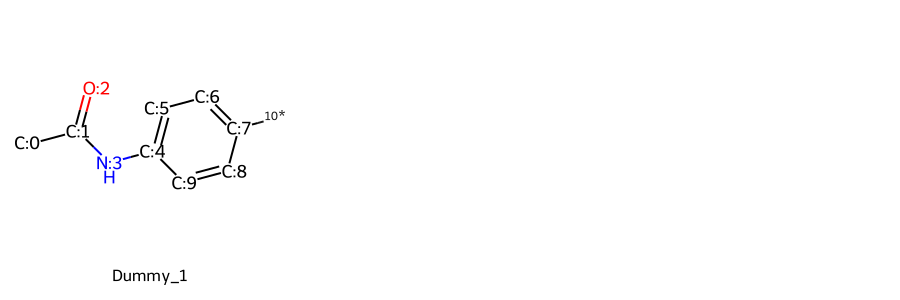


Generated molecular analogues:


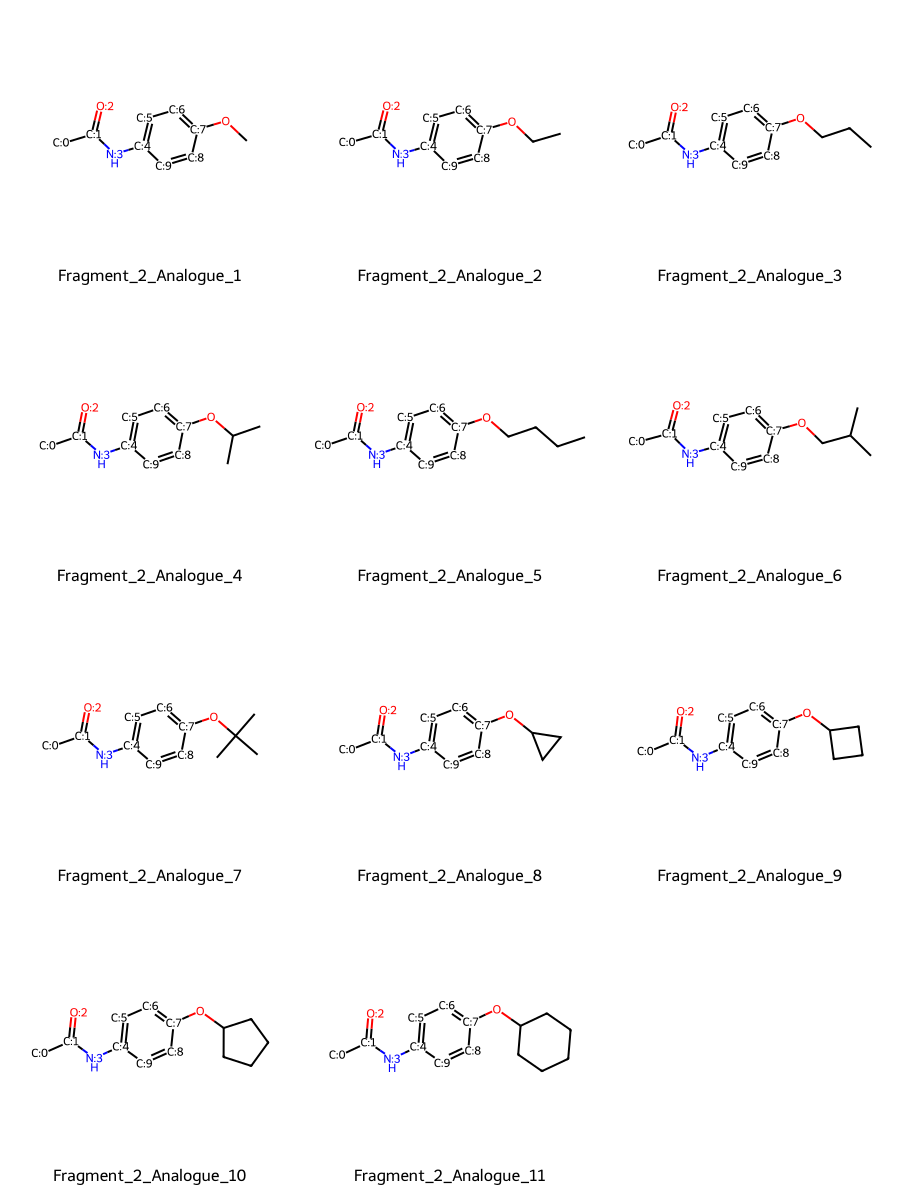

In [26]:
# -------------------------------------------------------
# INITIALIZE LIBRARIES
# -------------------------------------------------------

molecule_library = {
    "Parent": parent_mol
}

fragment_replacementlibrary = []
dummies = []
analogue_library = {}

fragment_counter = 0


# -------------------------------------------------------
# MAIN INTERACTIVE LOOP
# -------------------------------------------------------

while True:

    print("\n-----------------------------")
    print("Available molecules:")
    print("-----------------------------")

    names = list(molecule_library.keys())

    for i, name in enumerate(names):
        print(i, ":", name)

    print("\nChoose an option:")
    print("1 - Fragment a molecule")
    print("2 - Replace a bond and create molecular analogues")
    print("3 - Display molecules")
    print("4 - Finish")

    choice = input("Enter choice: ").strip()

    # ---------------------------------------------------
    # FINISH
    # ---------------------------------------------------

    if choice == "4":
        break

    # ---------------------------------------------------
    # DISPLAY MOLECULE LIBRARY
    # ---------------------------------------------------

    elif choice == "3":

        names = list(molecule_library.keys())
        molecules = list(molecule_library.values())

        img = Draw.MolsToGridImage(
            molecules,
            molsPerRow=3,
            subImgSize=(300, 300),
            legends=names
        )

        display(img)

        continue

    # ---------------------------------------------------
    # SELECT MOLECULE
    # ---------------------------------------------------

    elif choice in ("1", "2"):

    # Select parent molecule from molecule library
    
        print("\nWhich molecule do you want to modify?")
    
        names = list(molecule_library.keys())
        molecule_num = []
    
        for i, name in enumerate(names):
            print(i, ":", name)
            molecule_num.append(i)
    
        molecule_number = int(
            input("Enter molecule number: ")
        )
    
        if molecule_number not in molecule_num:
            print("Enter a valid number")
    
        else:
    
            parent_name = names[molecule_number]
        
            parent = molecule_library[parent_name]
        
        
    # Display selected molecule
        
            print("\nSelected molecule:", parent_name)
    
            draw_with_original_bond_indices(parent)

        # ------------------------------------------------
        # SELECT BONDS
        # ------------------------------------------------

        if choice == "1":
            atom1_idx = int(input("\nEnter first atom index of bond: "))
                
            atom2_idx = int(input("Enter second atom index of bond: "))
            
            idx1 = find_current_idx(parent, atom1_idx)
            idx2 = find_current_idx(parent, atom2_idx)
                
            # Check whether bond exists between the selected atoms
              
            bond = parent.GetBondBetweenAtoms(idx1, idx2)
                
            if bond is None:
                
                print("\nNo bond exists between these atoms.")
                
                continue
            
            # Make editable copy
            
            rw_mol = Chem.RWMol(parent)  
            
             # Break bond
            
            rw_mol.RemoveBond(idx1,idx2)
            
            # Sanitize
                
            try:
                
                 Chem.SanitizeMol(rw_mol)
                
            except Exception as e:
                
                print("\nSanitization failed:")
                print(e)
                
                continue
            
            # Fragmenting the molecule
            
            fragments = Chem.GetMolFrags(rw_mol, asMols=True)


        else:
            try:
                num_bonds = int(
                    input("How many groups do you want to replace? ")
                )

            except ValueError:
                print("Enter a valid integer.")
                continue

            if num_bonds <= 0:
                print("Enter at least one bond.")
                continue

            bond_indices = []

            invalid_selection = False

            for i in range(num_bonds):

                try:
                    bond_idx = int(
                        input(
                            f"\nEnter original bond index {i + 1}: "
                        )
                    )

                    current_bond_idx = find_current_bond_idx(
                        parent,
                        bond_idx
                    )

                    if current_bond_idx is None:
                        raise ValueError("Bond not found.")

                    bond = parent.GetBondWithIdx(
                        current_bond_idx
                    )

                    if bond is None:
                        raise ValueError("Bond not found.")

                    if current_bond_idx in bond_indices:
                        raise ValueError("Bond already selected.")

                    bond_indices.append(current_bond_idx)

                except (ValueError, RuntimeError, IndexError) as e:

                    print("Invalid bond selection:", e)

                    invalid_selection = True
                    break

                if invalid_selection:
                    continue

            # FRAGMENT SELECTED BONDS

            fragmented_mol = Chem.FragmentOnBonds(
                parent,
                bond_indices,
                addDummies=True
            )

            fragments = Chem.GetMolFrags(
                fragmented_mol,
                asMols=True
            )

        # ------------------------------------------------
        # IDENTIFY CORE FRAGMENT
        # ------------------------------------------------

        core_fragment = None

        for frag in fragments:

            if frag.HasSubstructMatch(core):

                core_fragment = frag
                break

        if core_fragment is None:

            print("Core was not found in the fragments.")
            continue

        fragment_counter += 1

        fragment_name = (
            f"{parent_name}_break_"
            f"{atom1_idx}_{atom2_idx}"
            if choice == "1"
            else f"Fragment_{fragment_counter}"
        )

        fragment_replacementlibrary.append(
            Chem.Mol(core_fragment)
            if choice == "1"
            else  dummies.append(Chem.Mol(core_fragment))
        )

        fragment_smiles = Chem.MolToSmiles(
            core_fragment
        )

        print("\nGenerated core fragment:")
        print(fragment_smiles)

        display(
            Draw.MolToImage(core_fragment)
        )

        
        # -------------------------------------------------------
        # OPTION 1: STORE FRAGMENT ONLY
        # -------------------------------------------------------

        if choice == "1":

            already_exists = False

            # Check whether fragment already exists in library

            for existing_mol in molecule_library.values():

                existing_smiles = Chem.MolToSmiles(existing_mol)

                if existing_smiles == fragment_smiles:

                    already_exists = True
                    break

            # Add fragment only if it is new

            if not already_exists:

                fragment_name = (
                    f"{parent_name}_break_"
                    f"{atom1_idx}_{atom2_idx}"
                )

                molecule_library[fragment_name] = Chem.Mol(
                    core_fragment
                )

                print(
                    f"\n{fragment_name} added to molecule library."
                )

            else:

                print("\nThis fragment already exists in molecule library.")

            continue

        else:
        # ------------------------------------------------
        # OPTION 2: SELECT REPLACEMENT GROUPS
        # ------------------------------------------------

            core_info = get_core_dummy_info(
                core_fragment
            )

            selected_categories = {}

            for info in core_info:

                core_neighbor_idx = info[
                    "core_dummy_neighbor_original_idx"
                ]

                print(
                    f"\nSelecting replacements for "
                    f"core neighbour index {core_neighbor_idx}"
                )

                # Select replacement categories

                replacement_categories = select_categories(
                    core_neighbor_idx
                )

                # Collect selected groups

                replacements = collect_replacements(
                    replacement_categories
                )

                # Prepare RDKit molecules

                prepared_groups = prepare_replacement_groups(
                    replacements
                )

                # Store separately for each dummy position

                selected_categories[
                    core_neighbor_idx
                ] = prepared_groups

            # ------------------------------------------------
            # DISPLAY SELECTED REPLACEMENTS
            # ------------------------------------------------

            print("\nSelected replacement groups:")

            for position, groups in selected_categories.items():

                print(f"\nCore neighbour index {position}:")

                for group in groups:

                    print(
                        f"  - {group['name']}: {group['smiles']}"
                    )

            # ------------------------------------------------
            # GENERATE ALL POSSIBLE COMBINATIONS
            # ------------------------------------------------

            positions = list(
                selected_categories.keys()
            )

            replacement_lists = list(
                selected_categories.values()
            )

            if not positions or any(
                len(groups) == 0 for groups in replacement_lists
            ):

                print(
                    "\nNo valid replacement combinations available."
                )

                continue

            combinations = product(
                *replacement_lists
            )

            print(
                f"\nGenerating analogues for {fragment_name}"
            )

            generated_count = 0

            # ------------------------------------------------
            # ATTACH REPLACEMENT GROUPS
            # ------------------------------------------------

            for combination_idx, combination in enumerate(
                combinations,
                start=1
            ):

                # Always start with a fresh core fragment

                current_mol = Chem.Mol(
                    core_fragment
                )

                replacement_names = []

                try:

                    for position, replacement_info in zip(
                        positions,
                        combination
                    ):

                        replacement_name = replacement_info[
                            "name"
                        ]

                        replacement_mol = replacement_info[
                            "mol"
                        ]

                        current_mol = attach_replacement(
                            current_mol,
                            Chem.Mol(replacement_mol),
                            position
                        )

                        replacement_names.append(
                            replacement_name
                        )

                    # ----------------------------------------
                    # VALIDATE GENERATED ANALOGUE
                    # ----------------------------------------

                    Chem.SanitizeMol(current_mol)

                    analogue_smiles = Chem.MolToSmiles(
                        current_mol
                    )

                    # ----------------------------------------
                    # STORE GENERATED ANALOGUE
                    # ----------------------------------------

                    analogue_name = (
                        f"{fragment_name}_"
                        f"Analogue_{combination_idx}"
                    )

                    analogue_library[
                        analogue_name
                    ] = Chem.Mol(current_mol)

                    molecule_library[
                        analogue_name
                    ] = Chem.Mol(current_mol)

                    generated_count += 1

                    print(
                        analogue_name,
                        "|",
                        ", ".join(replacement_names),
                        "|",
                        analogue_smiles
                    )

                except (
                    ValueError,
                    RuntimeError,
                    Chem.rdchem.MolSanitizeException
                ) as e:

                    print(
                        f"Skipping combination "
                        f"{combination_idx}: {e}"
                    )

            print(
                f"\nSuccessfully generated "
                f"{generated_count} analogues."
            )

    else:

        print("\nInvalid choice. Select 1, 2, 3 or 4.")


# -------------------------------------------------------
# FINAL RESULTS
# -------------------------------------------------------

print("\n==========================================")
print("FINAL RESULTS")
print("==========================================")

print(
    "Number of generated fragments:",
    len(fragment_replacementlibrary)
)

print(
    "Number of generated analogues:",
    len(analogue_library)
)

print(
    "Total molecules in library:",
    len(molecule_library)
)

print(
    "Number of generated dummies:",
    len(dummies)            
)


# -------------------------------------------------------
# DISPLAY GENERATED FRAGMENTS
# -------------------------------------------------------

if fragment_replacementlibrary:

    print("\nGenerated fragments:")

    fragment_names = [
        f"Fragment_{i + 1}"
        for i in range(len(fragment_replacementlibrary))
    ]

    display(
        Draw.MolsToGridImage(
            fragment_replacementlibrary,
            legends=fragment_names,
            molsPerRow=3,
            subImgSize=(300, 300)
        )
    )

# -------------------------------------------------------
# DISPLAY GENERATED DUMMIES
# -------------------------------------------------------
if dummies:

    print("\nGenerated dummies:")

    dummy_names = [
        f"Dummy_{i + 1}"
        for i in range(len(dummies))
    ]

    display(
        Draw.MolsToGridImage(
            dummies,
            legends=dummy_names,
            molsPerRow=3,
            subImgSize=(300, 300)
        )
    )   
# -------------------------------------------------------
# DISPLAY GENERATED ANALOGUES
# -------------------------------------------------------

if analogue_library:

    print("\nGenerated molecular analogues:")

    # Create fresh copies for drawing
    drawing_molecules = []

    for mol in analogue_library.values():

        mol_copy = Chem.Mol(mol)

        # Remove existing conformers and regenerate 2D coordinates
        mol_copy.RemoveAllConformers()

        rdDepictor.Compute2DCoords(mol_copy)

        drawing_molecules.append(mol_copy)

    # Display
    if drawing_molecules:

        display(
            Draw.MolsToGridImage(
                drawing_molecules,
                legends=analogue_library.keys(),
                molsPerRow=3,
                subImgSize=(300, 300),
                maxMols=len(drawing_molecules),
                useSVG=True
            )
        )
